# Recorded signals over time

Plots every signal in the ECG, acceleration, and vitals CSV files from session `2026-11-18T21-04-47Z`. Run all cells with a Python kernel that has Matplotlib, NumPy, and SciPy installed (`python -m pip install matplotlib numpy scipy`). Change `SESSION_NAME` below to plot another session.

The x axis is the board's microsecond timestamp converted to seconds. This recording contains clock jumps, so each increasing-time segment is drawn separately. Without host timestamps, time across a board reset cannot be reconstructed.

In [3]:
from pathlib import Path
import csv
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

SESSION_NAME = "2026-11-19T21-09-24Z"

# Works when Jupyter starts in the repository root or SerialAnalysis folder.
session_roots = [Path.cwd() / "sessions", Path.cwd() / "SerialAnalysis" / "sessions", Path.cwd() / ".." / "sessions"]
session_dir = next((root / SESSION_NAME for root in session_roots if (root / SESSION_NAME).is_dir()), None)
if session_dir is None:
    raise FileNotFoundError(f"Session {SESSION_NAME} not found under: {session_roots}")
print(f"Loading {session_dir.resolve()}")

Loading C:\Users\asher\projects\ece198\sessions\2026-11-19T21-09-24Z


In [4]:
def read_signals(path):
    with path.open(newline="", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file, skipinitialspace=True)
        columns = [name.strip() for name in reader.fieldnames or []]
        if not columns or columns[0] != "board_us":
            raise ValueError(f"Expected board_us as the first column in {path}")
        signals = {name: [] for name in columns[1:]}
        times = []
        for row in reader:
            times.append(float(row[reader.fieldnames[0]]) / 1_000_000)
            for name in columns[1:]:
                signals[name].append(float(row[name]))
    return times, signals

recordings = {}
for group in ("ecg", "acceleration", "vitals"):
    path = session_dir / f"{group}.csv"
    recordings[group] = read_signals(path)
    print(f"{path.name}: {len(recordings[group][0]):,} samples")

ecg.csv: 10,800 samples
acceleration.csv: 0 samples
vitals.csv: 49 samples


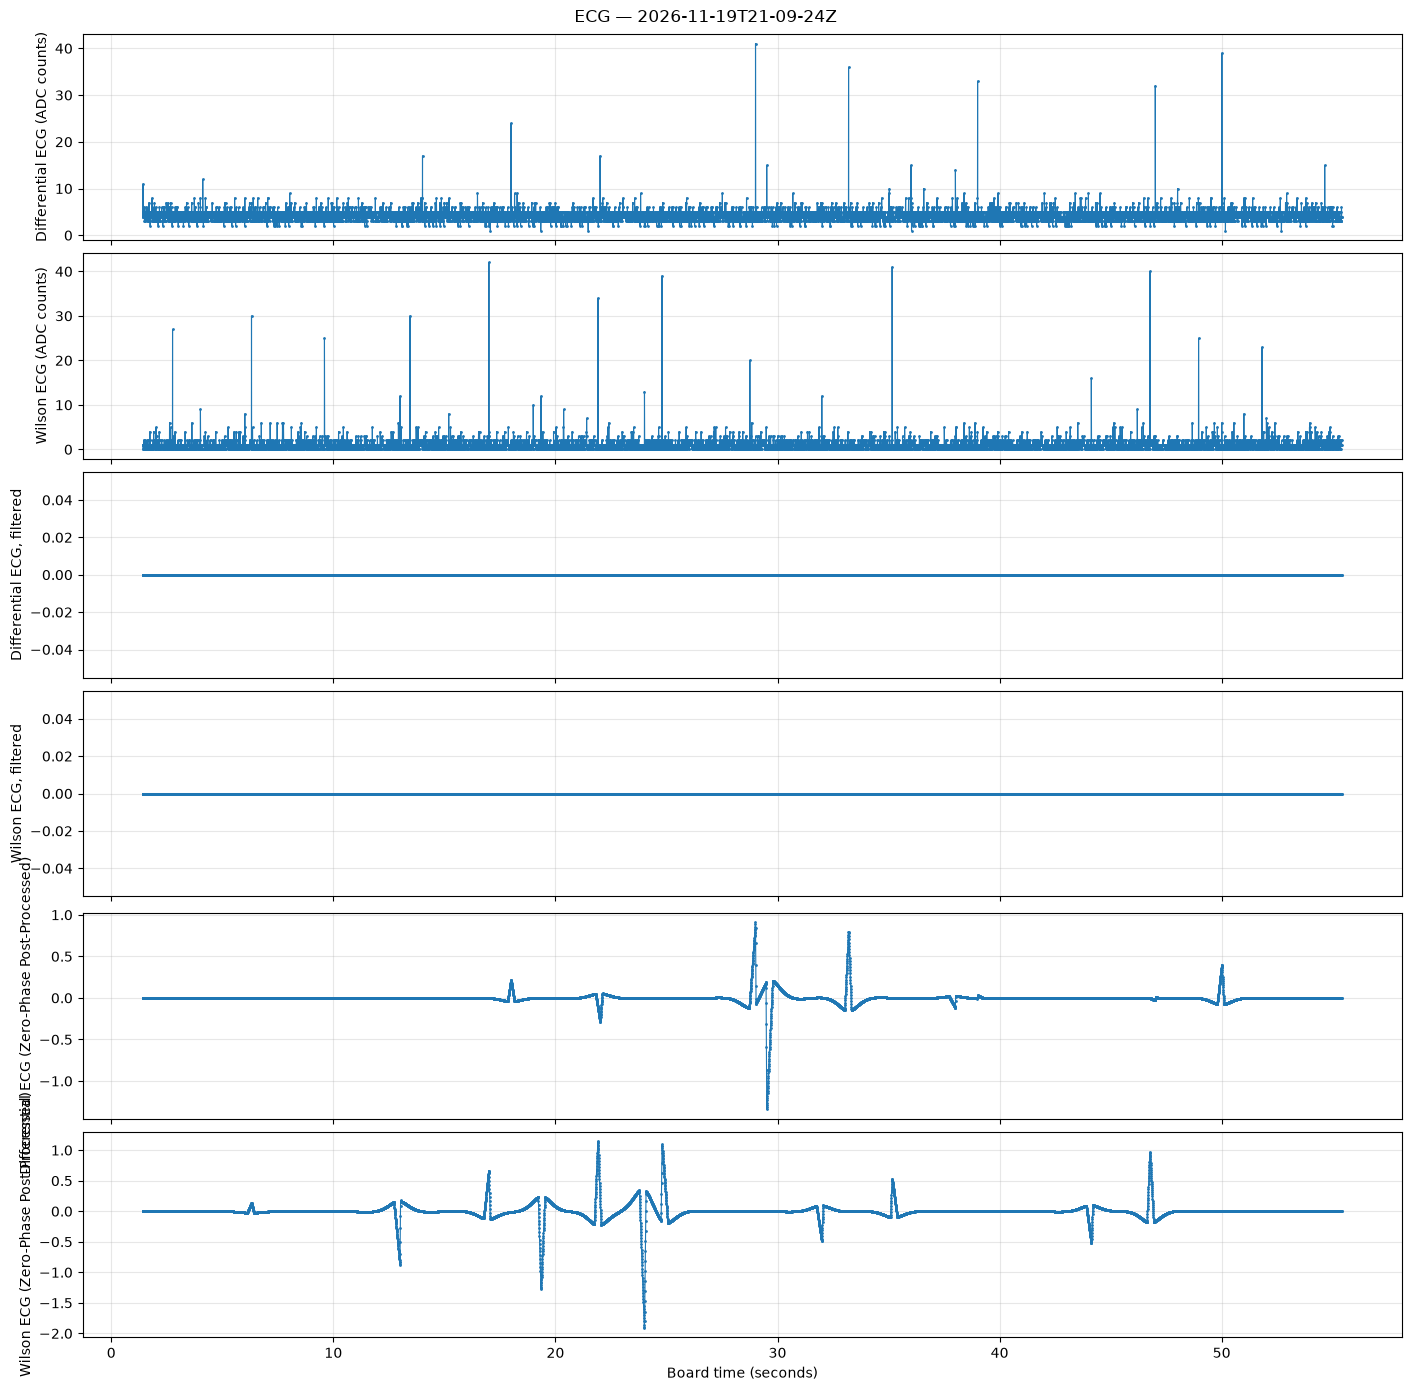

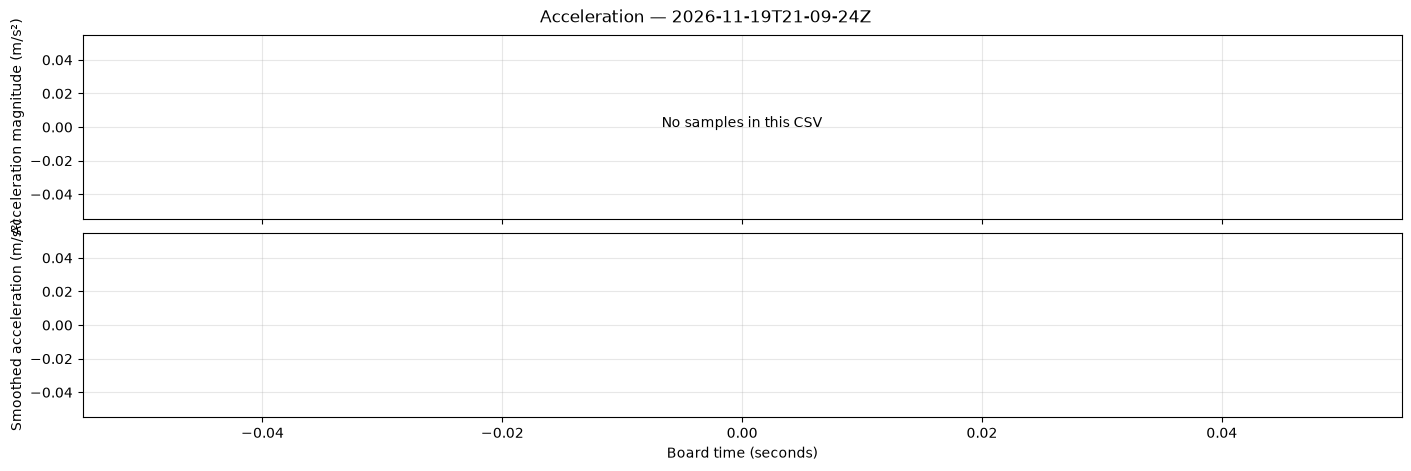

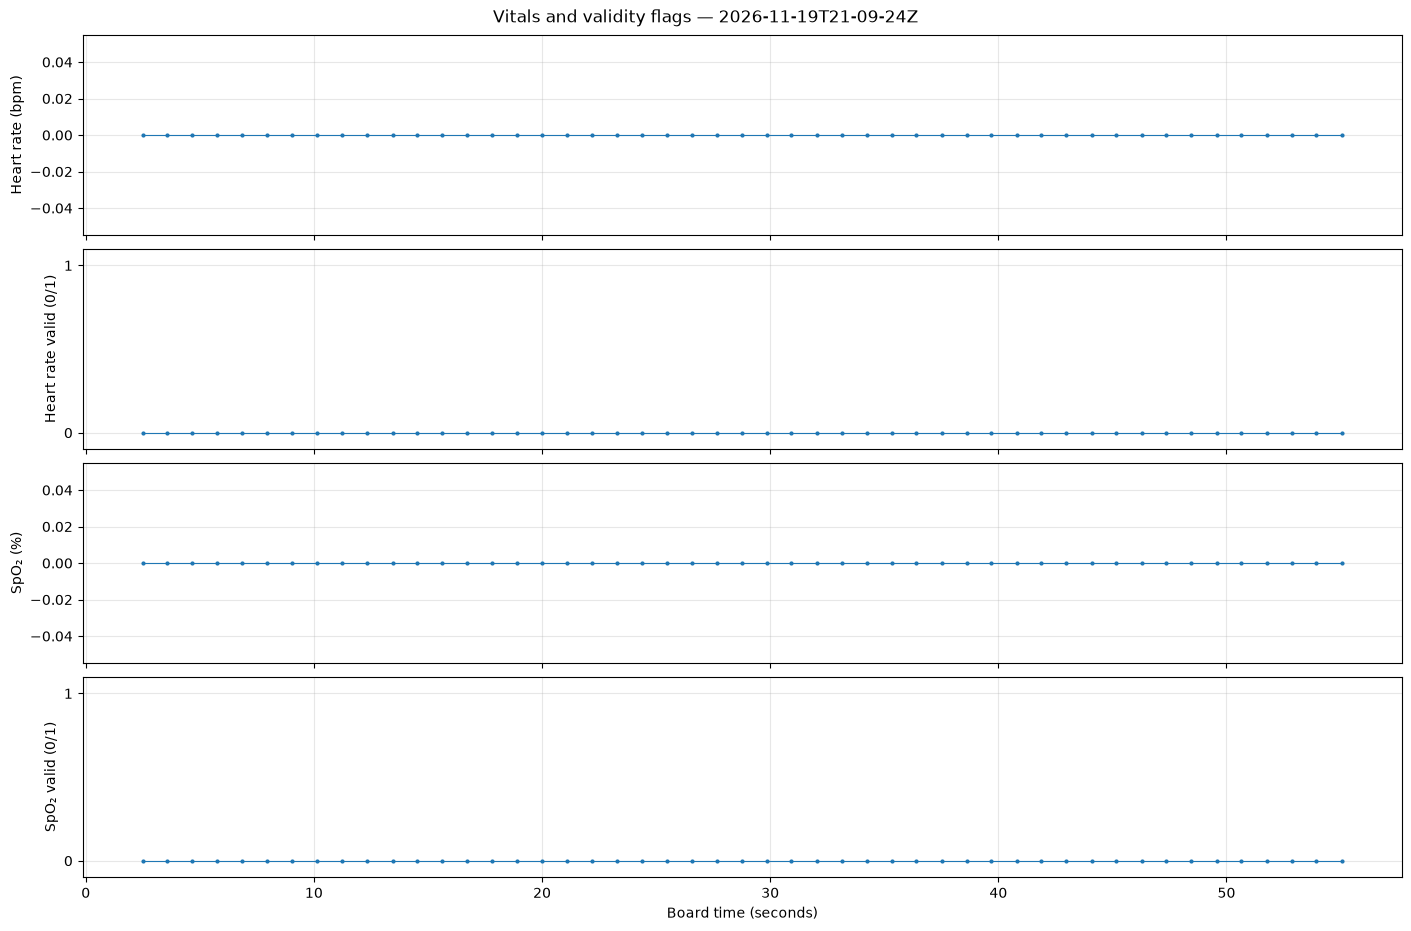

In [5]:
labels = {
    "diff_raw": "Differential ECG (ADC counts)",
    "wilson_raw": "Wilson ECG (ADC counts)",
    "diff_filtered": "Differential ECG, filtered",
    "wilson_filtered": "Wilson ECG, filtered",
    "diff_zero_phase": "Differential ECG (Zero-Phase Post-Processed)",
    "wilson_zero_phase": "Wilson ECG (Zero-Phase Post-Processed)",
    "magnitude_m_s2": "Acceleration magnitude (m/s²)",
    "smoothed_m_s2": "Smoothed acceleration (m/s²)",
    "heart_rate_bpm": "Heart rate (bpm)",
    "heart_rate_valid": "Heart rate valid (0/1)",
    "spo2_percent": "SpO₂ (%)",
    "spo2_valid": "SpO₂ valid (0/1)",
}

def time_segments(times):
    starts = [0] + [i for i in range(1, len(times)) if times[i] < times[i - 1]]
    return [slice(start, end) for start, end in zip(starts, starts[1:] + [len(times)])]

def zero_phase_clean_segment(raw_segment, fs=200.0):
    sig = np.asarray(raw_segment, dtype=np.float64)
    if len(sig) < 30:
        return sig - np.mean(sig)
    adc_max = 16383.0 if np.max(sig) > 1024 else 1023.0
    margin = max(5.0, adc_max * 0.01)
    clipped = (sig <= margin) | (sig >= (adc_max - margin))
    if np.any(clipped) and not np.all(clipped):
        idx = np.arange(len(sig))
        sig[clipped] = np.interp(idx[clipped], idx[~clipped], sig[~clipped])

    # Two-stage median filter removes motion baseline wander
    w1 = min(int(0.2 * fs) | 1, (len(sig) - 1) | 1)
    w2 = min(int(0.6 * fs) | 1, (len(sig) - 1) | 1)
    if w1 >= 3 and w2 >= 3:
        baseline = signal.medfilt(signal.medfilt(sig, w1), w2)
        sig = sig - baseline

    # Zero-phase 60 Hz notch + 2nd-order 0.5-40 Hz Butterworth bandpass
    b_n, a_n = signal.iirnotch(60.0, Q=30.0, fs=fs)
    sig = signal.filtfilt(b_n, a_n, sig)
    sos = signal.butter(2, [0.5, 40.0], btype="bandpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, sig)

# Compute zero-phase post-processed channels per contiguous time segment
ecg_times, ecg_signals = recordings["ecg"]
if ecg_times:
    ecg_segs = time_segments(ecg_times)
    for raw_key, zp_key in (("diff_raw", "diff_zero_phase"), ("wilson_raw", "wilson_zero_phase")):
        if raw_key in ecg_signals:
            zp_out = np.zeros(len(ecg_times))
            for seg in ecg_segs:
                zp_out[seg] = zero_phase_clean_segment(ecg_signals[raw_key][seg])
            ecg_signals[zp_key] = zp_out.tolist()

def plot_group(group, title):
    times, signals = recordings[group]
    fig, axes = plt.subplots(len(signals), 1, sharex=True, figsize=(14, 2.3 * len(signals)), layout="constrained")
    if len(signals) == 1:
        axes = [axes]
    segments = time_segments(times)
    for ax, (name, values) in zip(axes, signals.items()):
        for number, segment in enumerate(segments, start=1):
            ax.plot(times[segment], values[segment], linewidth=0.8,
                    marker=".", markersize=2 if len(times) > 1000 else 4,
                    label=f"Time segment {number}")
        ax.set_ylabel(labels.get(name, name))
        ax.grid(alpha=0.3)
        if name.endswith("_valid"):
            ax.set_yticks([0, 1])
            ax.set_ylim(-0.1, 1.1)
    if not times:
        axes[0].text(0.5, 0.5, "No samples in this CSV", transform=axes[0].transAxes, ha="center")
    elif len(segments) > 1:
        axes[0].legend(loc="best", fontsize=8)
    axes[-1].set_xlabel("Board time (seconds)")
    fig.suptitle(f"{title} — {SESSION_NAME}")
    plt.show()

plot_group("ecg", "ECG")
plot_group("acceleration", "Acceleration")
plot_group("vitals", "Vitals and validity flags")